## Setup

In [1]:
%pip install -q tensorflow-datasets importlib-resources

Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import pathlib
import numpy as np
import PIL
import PIL.Image
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

print(tf.__version__)

2.22.0-rc0


## 1. Get the dataset

Run **one** of the two options below.

**Option A (automatic download):**

In [3]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file("flower_photos.tgz", origin=dataset_url, extract=True, cache_dir=".", cache_subdir="data")

# Find the extracted flower_photos folder wherever Keras put it
candidates = [pathlib.Path("data/flower_photos"), pathlib.Path(archive) / "flower_photos", pathlib.Path(archive).parent / "flower_photos"]
data_dir = next(p for p in candidates if p.is_dir())
print("Dataset folder:", data_dir)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 76s 0us/step
Dataset folder: data\flower_photos_extracted\flower_photos


**Option B (manual):** if Option A fails, download the `.tgz` from the link above in your browser, put it next to this notebook, then run:

In [4]:
# import tarfile
# with tarfile.open("flower_photos.tgz") as t:
#     t.extractall("data")
# data_dir = pathlib.Path("data/flower_photos")

In [5]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)   # expected: 3670

3670


Each folder holds one flower type. Here are two roses:

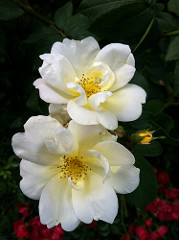

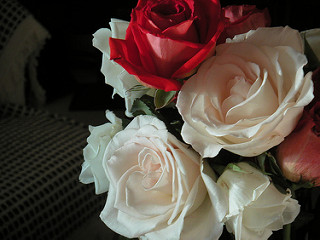

In [6]:
roses = list(data_dir.glob('roses/*'))
display(PIL.Image.open(str(roses[0])))
display(PIL.Image.open(str(roses[1])))

## 2. Load data with a Keras utility

In [7]:
batch_size = 32
img_height = 180
img_width = 180

In [8]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=123,
    image_size=(img_height, img_width), batch_size=batch_size)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=123,
    image_size=(img_height, img_width), batch_size=batch_size)

class_names = train_ds.class_names
print(class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


### Visualize the data

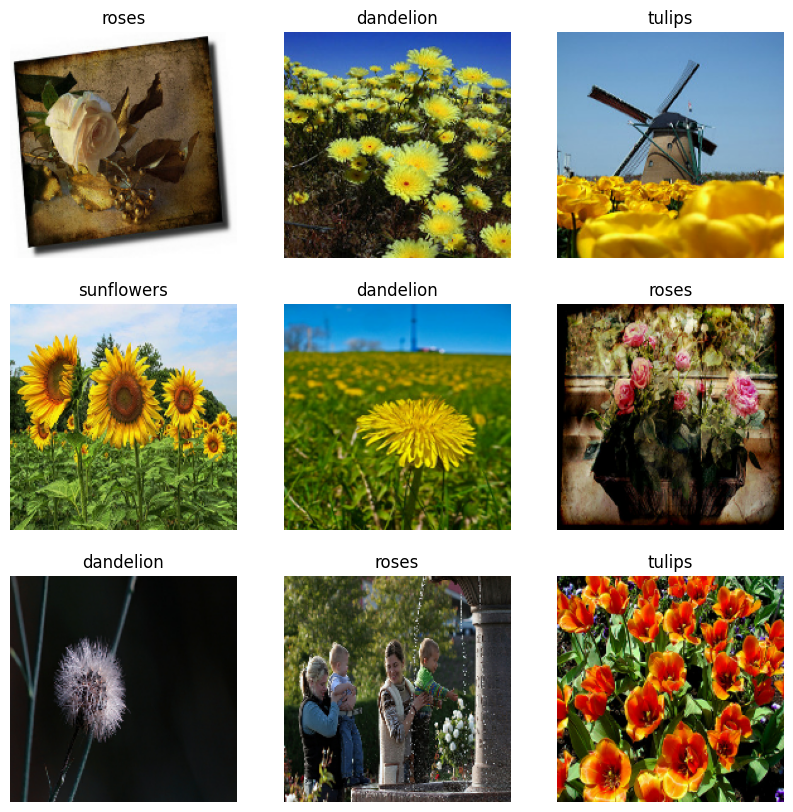

In [9]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [10]:
for image_batch, labels_batch in train_ds:
    print(image_batch.shape)   # (32, 180, 180, 3)
    print(labels_batch.shape)  # (32,)
    break

(32, 180, 180, 3)
(32,)


### Standardize the data (pixel values to [0, 1])

In [11]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
print(np.min(first_image), np.max(first_image))

0.0 0.96902645


### Configure the dataset for performance

In [12]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

### Train a simple model (3 epochs, so it runs quickly)

In [13]:
num_classes = 5

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'])

model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3


c:\Users\nani8\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 221ms/step - accuracy: 0.4353 - loss: 1.2968 - val_accuracy: 0.5777 - val_loss: 1.0583
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 194ms/step - accuracy: 0.6052 - loss: 0.9880 - val_accuracy: 0.6090 - val_loss: 0.9348
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 17s 183ms/step - accuracy: 0.6778 - loss: 0.8303 - val_accuracy: 0.6335 - val_loss: 0.9056


The validation accuracy is lower than the training accuracy, which means the model is overfitting. That is expected for this untuned model.

## 3. Using tf.data for finer control

In [14]:
list_ds = tf.data.Dataset.list_files(str(data_dir / '*/*'), shuffle=False)
list_ds = list_ds.shuffle(image_count, reshuffle_each_iteration=False)

for f in list_ds.take(5):
    print(f.numpy())

b'data\\flower_photos_extracted\\flower_photos\\daisy\\19834392829_7d697871f6.jpg'
b'data\\flower_photos_extracted\\flower_photos\\sunflowers\\22419079265_8902cddb7d_n.jpg'
b'data\\flower_photos_extracted\\flower_photos\\daisy\\11891885265_ccefec7284_n.jpg'
b'data\\flower_photos_extracted\\flower_photos\\dandelion\\7196409186_a59957ce0b_m.jpg'
b'data\\flower_photos_extracted\\flower_photos\\dandelion\\177851662_b2622b4238_n.jpg'


In [15]:
class_names = np.array(sorted([item.name for item in data_dir.glob('*') if item.is_dir()]))
print(class_names)

['daisy' 'dandelion' 'roses' 'sunflowers' 'tulips']


In [16]:
val_size = int(image_count * 0.2)
train_ds = list_ds.skip(val_size)
val_ds = list_ds.take(val_size)

print(tf.data.experimental.cardinality(train_ds).numpy())
print(tf.data.experimental.cardinality(val_ds).numpy())

2936
734


In [17]:
def get_label(file_path):
    parts = tf.strings.split(file_path, os.path.sep)
    one_hot = parts[-2] == class_names
    return tf.argmax(one_hot)

def decode_img(img):
    img = tf.io.decode_jpeg(img, channels=3)
    return tf.image.resize(img, [img_height, img_width])

def process_path(file_path):
    label = get_label(file_path)
    img = tf.io.read_file(file_path)
    img = decode_img(img)
    return img, label

train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=AUTOTUNE)

for image, label in train_ds.take(1):
    print("Image shape: ", image.numpy().shape)
    print("Label: ", label.numpy())

Image shape:  (180, 180, 3)
Label:  3


In [18]:
def configure_for_performance(ds):
    ds = ds.cache()
    ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = configure_for_performance(train_ds)
val_ds = configure_for_performance(val_ds)

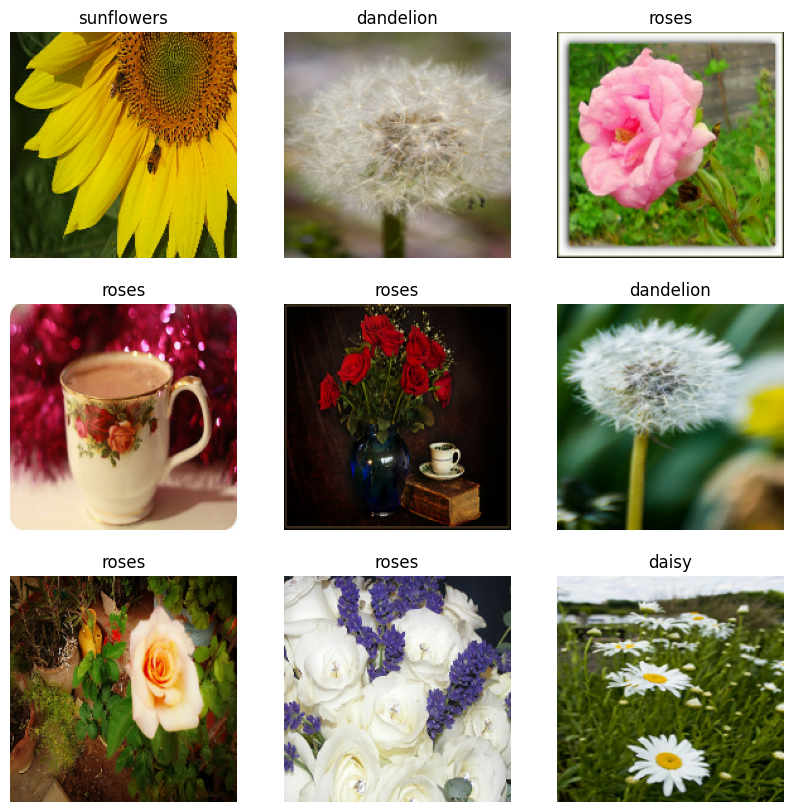

In [19]:
image_batch, label_batch = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.title(class_names[label_batch[i]])
    plt.axis("off")
plt.show()

### Continue training the model

In [20]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 19s 194ms/step - accuracy: 0.7337 - loss: 0.7097 - val_accuracy: 0.7616 - val_loss: 0.7027
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 171ms/step - accuracy: 0.8161 - loss: 0.5155 - val_accuracy: 0.7289 - val_loss: 0.6945
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 16s 178ms/step - accuracy: 0.8842 - loss: 0.3339 - val_accuracy: 0.7044 - val_loss: 0.8244


## 4. Using TensorFlow Datasets

`tfds` downloads the same flowers data (`tf_flowers`) itself. This needs internet access and is skipped quietly if it fails.

In [21]:
(train_ds, val_ds, test_ds), metadata = tfds.load(
    'tf_flowers',
    split=['train[:80%]', 'train[80%:90%]', 'train[90%:]'],
    with_info=True,
    as_supervised=True,
)

num_classes = metadata.features['label'].num_classes
print(num_classes)

c:\Users\nani8\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 100%|██████████| 1/1 [01:36<00:00, 96.07s/ url]
                                                                        

Dataset tf_flowers downloaded and prepared to C:\Users\nani8\tensorflow_datasets\tf_flowers\3.0.1. Subsequent calls will reuse this data.
5


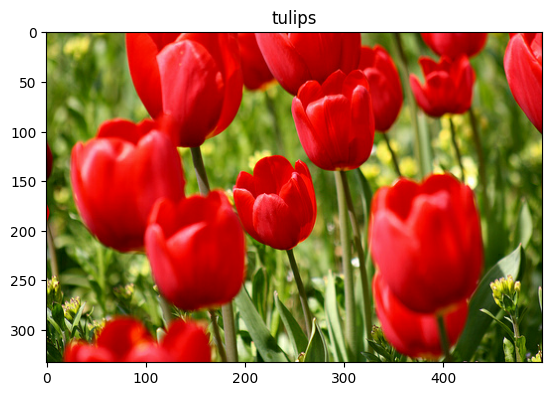

In [22]:
get_label_name = metadata.features['label'].int2str

image, label = next(iter(train_ds))
_ = plt.imshow(image)
_ = plt.title(get_label_name(label))
plt.show()

In [23]:
# tfds images have different sizes, so resize before batching
def resize_img(img, label):
    return tf.image.resize(img, [img_height, img_width]), label

train_ds = configure_for_performance(train_ds.map(resize_img, num_parallel_calls=AUTOTUNE))
val_ds = configure_for_performance(val_ds.map(resize_img, num_parallel_calls=AUTOTUNE))
test_ds = configure_for_performance(test_ds.map(resize_img, num_parallel_calls=AUTOTUNE))

loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {acc:.1%}")

Test accuracy: 24.3%
